# Analyse de transactions mobile money

Ce notebook reprend la méthode de mon projet TARDIS (analyse des retards SNCF) et l'applique à
des **transactions mobile money** (envois, retraits, paiements de facture, achats de crédit) dans
7 villes du Bénin, sur juillet et août 2026.

⚠️ Les données sont **fictives** : elles sont générées par `generate_data.py`, avec des défauts
ajoutés exprès (doublons, montants vides ou négatifs, deux formats de date, villes mal écrites).
Les conclusions ne décrivent donc pas un vrai opérateur : le but est de montrer la **méthode**.

- **Étape 1 : Nettoyage des données.** On charge le fichier brut, on corrige tout ce qui ne va
  pas, on crée quelques colonnes utiles, puis on exporte le résultat dans
  `cleaned_transactions.csv`.
- **Étape 2 : Visualisation et analyse.** On cherche **quand**, **où** et **quoi** : les heures
  de pic, les villes et les services les plus utilisés, les montants, et surtout **quand les
  transactions échouent**.

---

## Étape 1 : Nettoyage des données

### 1.1 Import des librairies

- `pandas` et `numpy` servent à manipuler les données ;
- `matplotlib` et `seaborn` servent à dessiner les graphiques ;
- `os` sert seulement à créer le dossier où on enregistre les graphiques.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

### 1.2 Chargement du dataset

Comme dans TARDIS, toutes les colonnes sont lues **en texte** (`dtype=str`) et **sans conversion
automatique des valeurs manquantes** (`keep_default_na=False`) : c'est nous qui décidons plus bas
ce qui est une valeur manquante et comment convertir les nombres et les dates.

In [2]:
df = pd.read_csv("transactions.csv", dtype=str, keep_default_na=False)
df.head(10)

,transaction_id,date_heure,type_operation,montant,ville,statut
0,TX000001,2026-07-01 01:13:24,retrait,126400,Cotonou,réussi
1,TX000002,01/07/2026 05:24:13,achat_credit,500,Cotonou,échoué
2,TX000003,2026-07-01 05:38:41,paiement_facture,8900,cotonou,réussi
3,TX000004,2026-07-01 05:47:35,retrait,40500,Porto-Novo,réussi
4,TX000005,2026-07-01 06:54:21,achat_credit,200,Abomey-Calavi,réussi
5,TX000006,2026-07-01 07:05:07,retrait,105300,Porto-Novo,réussi
6,TX000007,2026-07-01 07:07:27,retrait,6100,Ouidah,réussi
7,TX000008,2026-07-01 07:13:00,envoi,21850,Abomey-Calavi,réussi
8,TX000009,01/07/2026 07:24:04,paiement_facture,8600,Cotonou,réussi
9,TX000010,2026-07-01 07:42:17,retrait,181300,cotonou,réussi


### 1.3 Inspection de la structure

In [3]:
print("Shape:", df.shape)
df.info()

Shape: (5100, 6)
<class 'pandas.DataFrame'>
RangeIndex: 5100 entries, 0 to 5099
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   transaction_id  5100 non-null   str  
 1   date_heure      5100 non-null   str  
 2   type_operation  5100 non-null   str  
 3   montant         5100 non-null   str  
 4   ville           5100 non-null   str  
 5   statut          5100 non-null   str  
dtypes: str(6)
memory usage: 518.6 KB


On regarde les valeurs différentes de chaque colonne texte, pour repérer les problèmes avant de
les corriger.

In [4]:
print("Types d'opération :", df["type_operation"].unique())
print("Statuts :", df["statut"].unique())
print("Nombre de villes différentes :", df["ville"].nunique())
print(df["ville"].unique())

Types d'opération : <ArrowStringArray>
['retrait', 'achat_credit', 'paiement_facture', 'envoi']
Length: 4, dtype: str
Statuts : <ArrowStringArray>
['réussi', 'échoué']
Length: 2, dtype: str
Nombre de villes différentes : 28
<ArrowStringArray>
[        'Cotonou',         'cotonou',      'Porto-Novo',   'Abomey-Calavi',
          'Ouidah',         'Parakou',         'COTONOU',         'Bohicon',
      'Natitingou',       ' Cotonou ',    ' Porto-Novo ',      'PORTO-NOVO',
         'PARAKOU',   'abomey-calavi',      'porto-novo',         'BOHICON',
 ' Abomey-Calavi ',    ' Natitingou ',          'OUIDAH',      'NATITINGOU',
         'parakou',          'ouidah',   'ABOMEY-CALAVI',         'bohicon',
       ' Parakou ',       ' Bohicon ',      'natitingou',        ' Ouidah ']
Length: 28, dtype: str


**Ce qu'on en retient :**

- Le fichier contient **5 100 lignes** et 6 colonnes, toutes lues en texte pour l'instant.
- Les types d'opération et les statuts sont propres : 4 types et 2 statuts, sans faute.
- La colonne `ville` est le premier problème visible : **28 noms différents** pour seulement 7 villes
  (`Cotonou`, `cotonou`, `COTONOU`, `" Cotonou "`...).

### 1.4 Valeurs manquantes

Une valeur manquante peut être une case vide ou un texte comme `"NA"` ou `"null"`. On retire
d'abord les espaces en trop (au début, à la fin, et les espaces multiples au milieu), puis on
remplace toutes ces valeurs par un vrai `NaN`.

In [5]:
valeurs_manquantes_texte = ["", "-", "na", "n/a", "nan", "none", "null"]

for col in df.columns:
    valeurs = df[col].str.split().str.join(" ")
    est_manquant = valeurs.str.lower().isin(valeurs_manquantes_texte)
    df[col] = valeurs.mask(est_manquant)

df.isna().sum()

transaction_id     0
date_heure         0
type_operation     0
montant           68
ville              0
statut             0
dtype: int64

**Ce qu'on en retient :**

- Seule la colonne `montant` a des trous : **68 montants vides**. Toutes les autres colonnes sont
  complètes.
- En retirant les espaces en trop, on a déjà corrigé une partie des villes (`" Cotonou "` devient
  `"Cotonou"`) : c'est pour ça qu'il n'en reste que 21 à l'étape suivante.

### 1.5 Uniformisation des noms de villes

Une même ville est écrite de plusieurs façons : `"Cotonou"`, `"COTONOU"`, `"cotonou"`,
`" Cotonou "`. Sans correction, Cotonou serait comptée comme quatre villes différentes.

Les espaces ont déjà été retirés à l'étape précédente. Il reste à mettre la **première lettre de
chaque mot en majuscule** avec `title()` (ça marche aussi avec les tirets : `"porto-novo"` devient
`"Porto-Novo"`). Une ville qui n'est pas dans la liste attendue devient une valeur manquante.

In [6]:
villes_attendues = [
    "Cotonou",
    "Abomey-Calavi",
    "Porto-Novo",
    "Parakou",
    "Bohicon",
    "Ouidah",
    "Natitingou",
]


def normaliser_ville(nom):
    if pd.isna(nom):
        return np.nan
    nom = nom.title()
    if nom not in villes_attendues:
        return np.nan
    return nom


avant = df["ville"].nunique()
df["ville"] = df["ville"].apply(normaliser_ville)
print("ville :", avant, "noms différents ->", df["ville"].nunique())

ville : 21 noms différents -> 7


### 1.6 Uniformisation et conversion de la colonne date_heure

Le fichier mélange deux formats de date :
- `2026-07-01 08:15:00` (année-mois-jour) ;
- `01/07/2026 08:15:00` (jour/mois/année).

Si on laisse pandas deviner, il peut confondre le jour et le mois (le 07/08 est-il le 7 août ou
le 8 juillet ?). On repère donc le format avec la présence d'un `/`, et on donne à pandas le
format exact. Une date illisible devient `NaT` (date manquante) au lieu de faire planter le
notebook.

In [7]:
def uniformiser_date(date_texte):
    if pd.isna(date_texte):
        return pd.NaT
    if "/" in date_texte:
        return pd.to_datetime(date_texte, format="%d/%m/%Y %H:%M:%S", errors="coerce")
    return pd.to_datetime(date_texte, format="%Y-%m-%d %H:%M:%S", errors="coerce")


nb_format_slash = df["date_heure"].str.contains("/").sum()
df["date_heure"] = df["date_heure"].apply(uniformiser_date)
df["date_heure"] = pd.to_datetime(df["date_heure"])

print("Dates au format jj/mm/aaaa converties :", nb_format_slash)
print("Dates illisibles :", df["date_heure"].isna().sum())
print("Période :", df["date_heure"].min(), "->", df["date_heure"].max())

Dates au format jj/mm/aaaa converties : 786
Dates illisibles : 0
Période : 2026-07-01 01:13:24 -> 2026-08-31 23:30:25


### 1.7 Conversion des montants

On convertit les montants en nombres avec `pd.to_numeric(..., errors="coerce")` : une valeur
impossible à lire devient `NaN` au lieu de faire planter la conversion.

Un montant ne peut pas être **négatif**. Comme dans TARDIS, on considère que c'est une erreur de
signe et on garde la **valeur absolue** (un retrait de `-5000` devient un retrait de `5000`).

In [8]:
df["montant"] = pd.to_numeric(df["montant"], errors="coerce")

nb_negatifs = (df["montant"] < 0).sum()
df["montant"] = df["montant"].abs()
print("Montants négatifs corrigés :", nb_negatifs)
print("Montants manquants :", df["montant"].isna().sum())

Montants négatifs corrigés : 59
Montants manquants : 68


### 1.8 Suppression des doublons

Maintenant que les villes, les dates et les montants sont écrits de la même façon, on peut
repérer les doublons :
- les lignes strictement identiques ;
- les lignes qui ont le même `transaction_id` : un identifiant doit être unique, on ne garde que
  la première.

Il faut le faire **avant** de remplir les montants manquants : sinon on comparerait des valeurs
inventées.

In [9]:
nb_doublons = df.duplicated().sum()
df = df.drop_duplicates()
nb_doublons_id = df.duplicated(subset=["transaction_id"]).sum()
df = df.drop_duplicates(subset=["transaction_id"])

print("Doublons stricts supprimés :", nb_doublons)
print("Doublons d'identifiant supprimés :", nb_doublons_id)
print("Shape après suppression des doublons:", df.shape)

Doublons stricts supprimés : 100
Doublons d'identifiant supprimés : 0
Shape après suppression des doublons: (5000, 6)


### 1.9 Traitement des valeurs manquantes

- `transaction_id`, `date_heure`, `type_operation`, `statut` : sans ces informations la ligne est
  inexploitable, on la supprime.
- `ville` manquante : on ne peut pas la deviner, on la remplace par `"Inconnue"` pour garder la
  transaction dans les autres calculs.
- `montant` manquant : on le remplit avec la **médiane du même type d'opération** (un achat de
  crédit ressemble surtout aux autres achats de crédit, pas à un retrait). La médiane est
  préférée à la moyenne parce qu'elle n'est pas tirée par les très gros montants.

In [10]:
colonnes_cles = ["transaction_id", "date_heure", "type_operation", "statut"]
df = df.dropna(subset=colonnes_cles)

df["ville"] = df["ville"].fillna("Inconnue")

nb_montants_manquants = df["montant"].isna().sum()
mediane_du_type = df.groupby("type_operation")["montant"].transform("median")
df["montant"] = df["montant"].fillna(mediane_du_type)

print("Montants remplis avec la médiane du type :", nb_montants_manquants)
print("Valeurs manquantes restantes :", df.isna().sum().sum())
print("Shape:", df.shape)

Montants remplis avec la médiane du type : 68
Valeurs manquantes restantes : 0
Shape: (5000, 6)


### 1.10 Contrôle de cohérence

On vérifie que chaque colonne ne contient que des valeurs possibles :
- 4 types d'opération et 2 statuts ;
- aucun montant nul ;
- toutes les dates dans la période attendue (juillet-août 2026).

In [11]:
types_attendus = ["envoi", "retrait", "paiement_facture", "achat_credit"]
statuts_attendus = ["réussi", "échoué"]

incoherent = ~df["type_operation"].isin(types_attendus)
incoherent = incoherent | ~df["statut"].isin(statuts_attendus)
incoherent = incoherent | (df["montant"] <= 0)
incoherent = incoherent | (df["date_heure"] < "2026-07-01")
incoherent = incoherent | (df["date_heure"] >= "2026-09-01")

print("Lignes incohérentes trouvées :", incoherent.sum())
df = df[~incoherent]

Lignes incohérentes trouvées : 0


### 1.11 Création de nouvelles variables (feature engineering)

On découpe la date en informations plus simples à analyser :
- `jour` (la date sans l'heure), `heure` (de 0 à 23) et `jour_semaine` ;
- `echec` : vaut 1 si la transaction a échoué, 0 sinon. La **moyenne** de cette colonne donne
  directement le **taux d'échec** ;
- `est_le_soir` : vrai si la transaction a lieu entre 19h et 21h.

In [12]:
noms_des_jours = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]

df["jour"] = df["date_heure"].dt.date
df["heure"] = df["date_heure"].dt.hour
df["jour_semaine"] = df["date_heure"].dt.dayofweek.map(lambda numero: noms_des_jours[numero])
df["echec"] = (df["statut"] == "échoué").astype(int)
df["est_le_soir"] = (df["heure"] >= 19) & (df["heure"] < 21)

df = df.sort_values("date_heure")
df.head()

,transaction_id,date_heure,type_operation,montant,ville,statut,jour,heure,jour_semaine,echec,est_le_soir
0,TX000001,2026-07-01 01:13:24,retrait,126400.0,Cotonou,réussi,2026-07-01,1,mercredi,0,False
1,TX000002,2026-07-01 05:24:13,achat_credit,500.0,Cotonou,échoué,2026-07-01,5,mercredi,1,False
2,TX000003,2026-07-01 05:38:41,paiement_facture,8900.0,Cotonou,réussi,2026-07-01,5,mercredi,0,False
3,TX000004,2026-07-01 05:47:35,retrait,40500.0,Porto-Novo,réussi,2026-07-01,5,mercredi,0,False
4,TX000005,2026-07-01 06:54:21,achat_credit,200.0,Abomey-Calavi,réussi,2026-07-01,6,mercredi,0,False


### 1.12 Export du dataset nettoyé

In [13]:
df.to_csv("cleaned_transactions.csv", index=False)
print("Dataset nettoyé :", df.shape[0], "lignes,", df.shape[1], "colonnes")

Dataset nettoyé : 5000 lignes, 11 colonnes


**Ce qu'on en retient :**

Bilan du nettoyage :
- **7 villes** au lieu de 28 noms différents ;
- **786 dates** au format jj/mm/aaaa converties, aucune date illisible ;
- **59 montants négatifs** corrigés et **68 montants vides** remplis avec la médiane de leur type ;
- **100 doublons** supprimés ;
- on passe de **5 100 lignes brutes à 5 000 transactions propres**, sans aucune valeur manquante.

---

## Étape 2 : Visualisation et analyse

Au programme :
- 2.1 Les indicateurs clés
- 2.2 Les heures de pic
- 2.3 Les jours de la semaine
- 2.4 Les services les plus utilisés
- 2.5 La répartition par ville
- 2.6 Les montants par type d'opération
- 2.7 Le taux d'échec par service et par heure
- 2.8 Zoom sur les paiements de facture le soir
- 2.9 Ce qu'il faut retenir

Chaque graphique est aussi enregistré dans le dossier `graphiques/` pour le README.

In [14]:
sns.set_theme(style="whitegrid")
os.makedirs("graphiques", exist_ok=True)

couleur = "steelblue"
couleur_alerte = "crimson"

### 2.1 Indicateurs clés

Le **volume** est la somme des montants des transactions **réussies** : une transaction échouée
n'a pas fait circuler d'argent.

In [15]:
nombre_transactions = len(df)
reussies = df[df["statut"] == "réussi"]
volume_total = reussies["montant"].sum()
taux_echec = df["echec"].mean() * 100

print("Nombre de transactions :", nombre_transactions)
print("Volume total réussi :", int(volume_total), "FCFA")
print("Montant moyen :", round(df["montant"].mean()), "FCFA")
print("Montant médian :", round(df["montant"].median()), "FCFA")
print("Taux d'échec global :", round(taux_echec, 1), "%")

Nombre de transactions : 5000
Volume total réussi : 230602225 FCFA
Montant moyen : 47684 FCFA
Montant médian : 33675 FCFA
Taux d'échec global : 3.5 %


**Ce qu'on en retient :**

- Sur deux mois, **5 000 transactions** ont fait circuler environ **230 millions de FCFA**.
- Le montant moyen (environ 47 700 FCFA) est au-dessus du montant médian (environ 33 700 FCFA) :
  quelques gros retraits et gros envois tirent la moyenne vers le haut.
- Globalement, **3,5 % des transactions échouent**, soit environ une sur trente.

### 2.2 Heures de pic

On compte le nombre de transactions pour chaque heure de la journée.

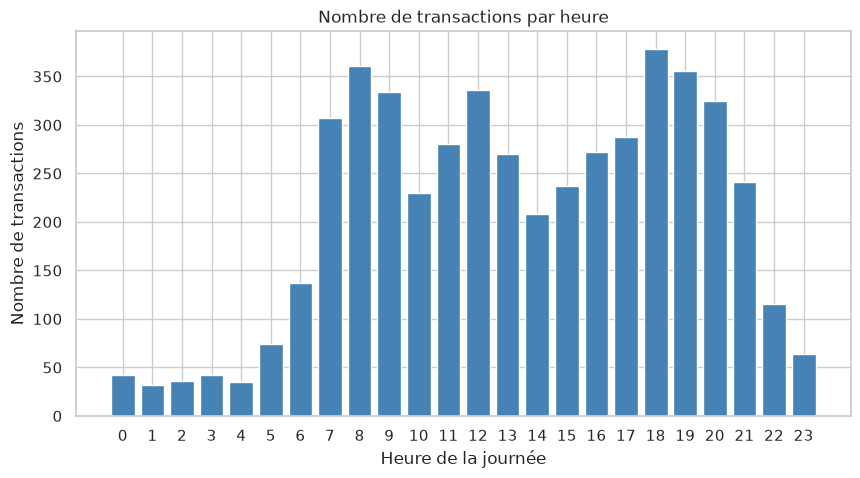

Les 3 heures les plus chargées :
heure
18    378
8     361
19    356
Name: transaction_id, dtype: int64


In [16]:
transactions_par_heure = df.groupby("heure")["transaction_id"].count()

plt.figure(figsize=(10, 5))
plt.bar(transactions_par_heure.index, transactions_par_heure.values, color=couleur)
plt.title("Nombre de transactions par heure")
plt.xlabel("Heure de la journée")
plt.ylabel("Nombre de transactions")
plt.xticks(range(24))
plt.savefig("graphiques/transactions_par_heure.png", dpi=100, bbox_inches="tight")
plt.show()

print("Les 3 heures les plus chargées :")
print(transactions_par_heure.sort_values(ascending=False).head(3))

**Ce qu'on en retient :**

- L'activité suit le rythme de la journée : presque rien la nuit, un **pic le matin vers 8h** et un
  **pic le soir entre 18h et 19h**, à la sortie du travail.
- Ce sont les moments où le système doit tenir la charge : une panne à 18h toucherait beaucoup plus
  de clients qu'une panne à 3h.

### 2.3 Jours de la semaine

Juillet et août 2026 ne contiennent pas le même nombre de lundis, de mardis... On calcule donc
une **moyenne par jour** plutôt qu'un total, pour que la comparaison soit juste.

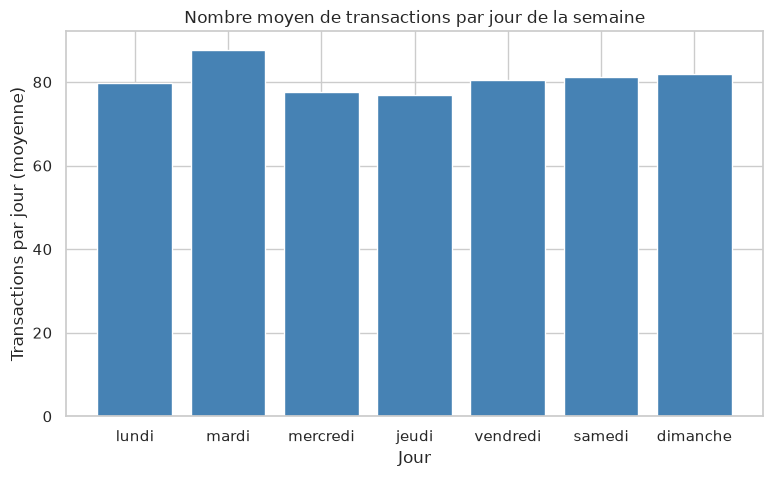

jour_semaine
lundi       79.8
mardi       87.8
mercredi    77.6
jeudi       76.8
vendredi    80.4
samedi      81.1
dimanche    81.9
Name: transaction_id, dtype: float64


In [17]:
transactions_par_jour = df.groupby(["jour", "jour_semaine"])["transaction_id"].count()
transactions_par_jour = transactions_par_jour.reset_index()
moyenne_par_jour_semaine = transactions_par_jour.groupby("jour_semaine")["transaction_id"].mean()
moyenne_par_jour_semaine = moyenne_par_jour_semaine.reindex(noms_des_jours)

plt.figure(figsize=(9, 5))
plt.bar(moyenne_par_jour_semaine.index, moyenne_par_jour_semaine.values, color=couleur)
plt.title("Nombre moyen de transactions par jour de la semaine")
plt.xlabel("Jour")
plt.ylabel("Transactions par jour (moyenne)")
plt.savefig("graphiques/transactions_par_jour.png", dpi=100, bbox_inches="tight")
plt.show()

print(moyenne_par_jour_semaine.round(1))

**Ce qu'on en retient :**

- Le nombre de transactions par jour est **à peu près le même** tous les jours de la semaine (entre
  77 et 88 en moyenne). Le mardi est un peu au-dessus, mais l'écart est faible.
- Dans ces données, l'heure compte donc beaucoup plus que le jour de la semaine.

### 2.4 Services les plus utilisés

On compare les services de deux façons : le **nombre** de transactions et le **volume** d'argent.
Ce sont deux grandeurs d'échelles très différentes, donc on fait deux graphiques côte à côte
plutôt qu'un seul graphique avec deux axes.

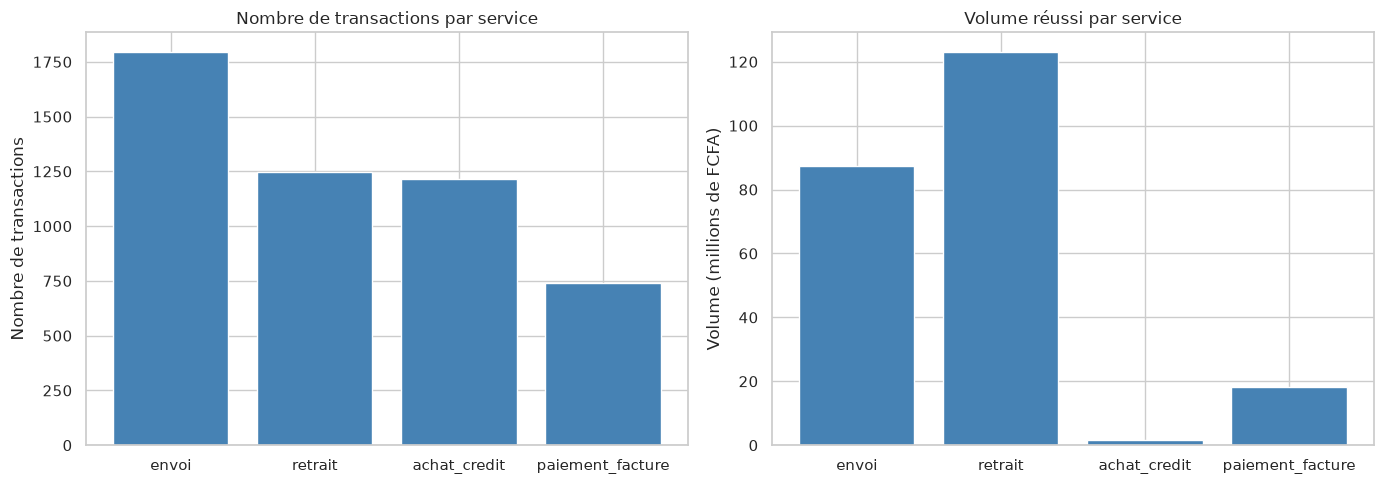

type_operation
envoi               35.9
retrait             24.9
achat_credit        24.3
paiement_facture    14.8
Name: count, dtype: float64


In [18]:
nombre_par_type = df["type_operation"].value_counts()
volume_par_type = reussies.groupby("type_operation")["montant"].sum()
volume_par_type = volume_par_type.reindex(nombre_par_type.index) / 1_000_000

figure, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(nombre_par_type.index, nombre_par_type.values, color=couleur)
axes[0].set_title("Nombre de transactions par service")
axes[0].set_ylabel("Nombre de transactions")

axes[1].bar(volume_par_type.index, volume_par_type.values, color=couleur)
axes[1].set_title("Volume réussi par service")
axes[1].set_ylabel("Volume (millions de FCFA)")

plt.tight_layout()
plt.savefig("graphiques/services.png", dpi=100, bbox_inches="tight")
plt.show()

pourcentage_par_type = nombre_par_type / len(df) * 100
print(pourcentage_par_type.round(1))

**Ce qu'on en retient :**

- L'**envoi d'argent** est le service le plus utilisé (environ 36 % des transactions), devant le
  retrait et l'achat de crédit (environ 25 % chacun). Le paiement de facture arrive en dernier
  (environ 15 %).
- Le classement change complètement quand on regarde l'argent : les **retraits** représentent le plus
  gros volume (plus de 120 millions de FCFA), alors que l'**achat de crédit**, très fréquent, ne pèse
  presque rien en volume (petits montants).
- Le nombre de transactions et le volume racontent donc deux histoires différentes : il faut
  regarder les deux.

### 2.5 Répartition par ville

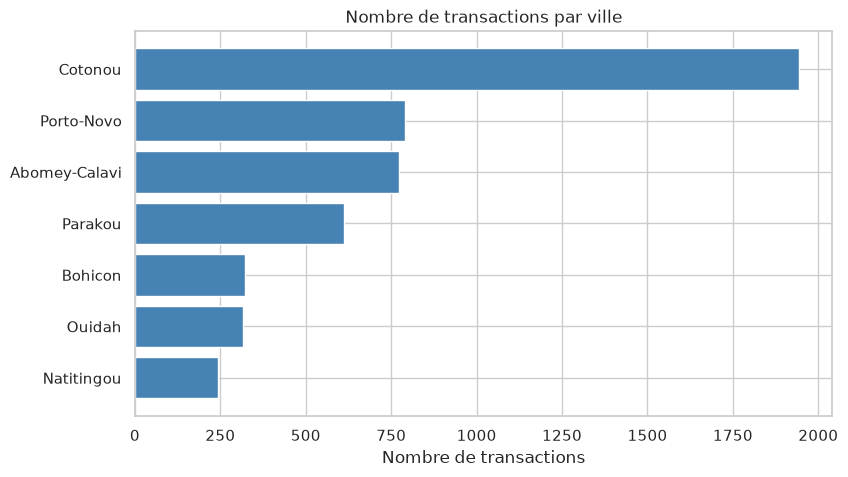

ville
Cotonou          38.9
Porto-Novo       15.8
Abomey-Calavi    15.4
Parakou          12.3
Bohicon           6.4
Ouidah            6.3
Natitingou        4.8
Name: count, dtype: float64


In [19]:
nombre_par_ville = df["ville"].value_counts().sort_values()

plt.figure(figsize=(9, 5))
plt.barh(nombre_par_ville.index, nombre_par_ville.values, color=couleur)
plt.title("Nombre de transactions par ville")
plt.xlabel("Nombre de transactions")
plt.savefig("graphiques/villes.png", dpi=100, bbox_inches="tight")
plt.show()

pourcentage_par_ville = nombre_par_ville.sort_values(ascending=False) / len(df) * 100
print(pourcentage_par_ville.round(1))

**Ce qu'on en retient :**

- **Cotonou** concentre à elle seule près de **4 transactions sur 10**.
- Viennent ensuite Porto-Novo et Abomey-Calavi (environ 15 % chacune), puis Parakou (12 %).
- Les villes plus petites ou plus éloignées (Bohicon, Ouidah, Natitingou) représentent chacune
  moins de 7 % des transactions.

### 2.6 Montants par type d'opération

Comme dans TARDIS, on utilise une **boîte à moustaches** : le trait au milieu est la médiane, la
boîte contient la moitié des valeurs, et les moustaches montrent l'étendue des valeurs
habituelles. On masque les valeurs extrêmes pour que les boîtes restent lisibles.

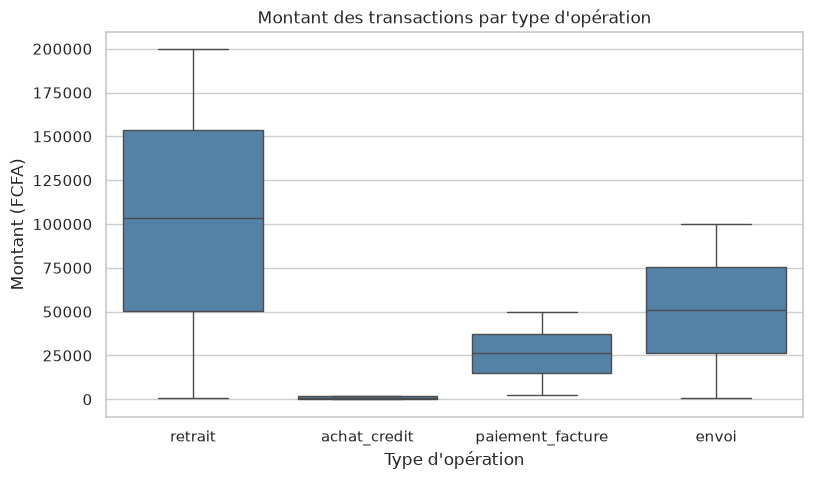

,mean,median
type_operation,,
achat_credit,1484.0,1000.0
envoi,50341.0,50825.0
paiement_facture,26090.0,26500.0
retrait,101780.0,103200.0


In [20]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="type_operation", y="montant", showfliers=False, color=couleur)
plt.title("Montant des transactions par type d'opération")
plt.xlabel("Type d'opération")
plt.ylabel("Montant (FCFA)")
plt.savefig("graphiques/montants.png", dpi=100, bbox_inches="tight")
plt.show()

montants_par_type = df.groupby("type_operation")["montant"].agg(["mean", "median"])
montants_par_type.round(0)

**Ce qu'on en retient :**

- Chaque service a sa propre échelle de montants : environ **1 000 FCFA** pour un achat de crédit,
  **26 000 FCFA** pour une facture, **50 000 FCFA** pour un envoi et **100 000 FCFA** pour un
  retrait (médianes).
- C'est ce qui justifie, à l'étape 1.9, d'avoir rempli les montants manquants avec la médiane **du
  même type** : la médiane globale (environ 33 700 FCFA) aurait été beaucoup trop haute pour un
  achat de crédit et trop basse pour un retrait.

### 2.7 Taux d'échec par service et par heure

C'est la question la plus utile pour un opérateur : **quand** et **sur quoi** les transactions
échouent-elles ?

On commence par le taux d'échec de chaque service. Puis on construit une **carte de chaleur**
(heatmap) : une ligne par service, une colonne par heure, et une case d'autant plus foncée que le
taux d'échec est élevé. Comme la colonne `echec` vaut 0 ou 1, sa moyenne donne directement le
taux d'échec.

In [21]:
taux_echec_par_type = df.groupby("type_operation")["echec"].mean() * 100
print("Taux d'échec par service (%) :")
print(taux_echec_par_type.round(1).sort_values(ascending=False))

Taux d'échec par service (%) :
type_operation
paiement_facture    5.7
achat_credit        3.3
envoi               3.2
retrait             2.8
Name: echec, dtype: float64


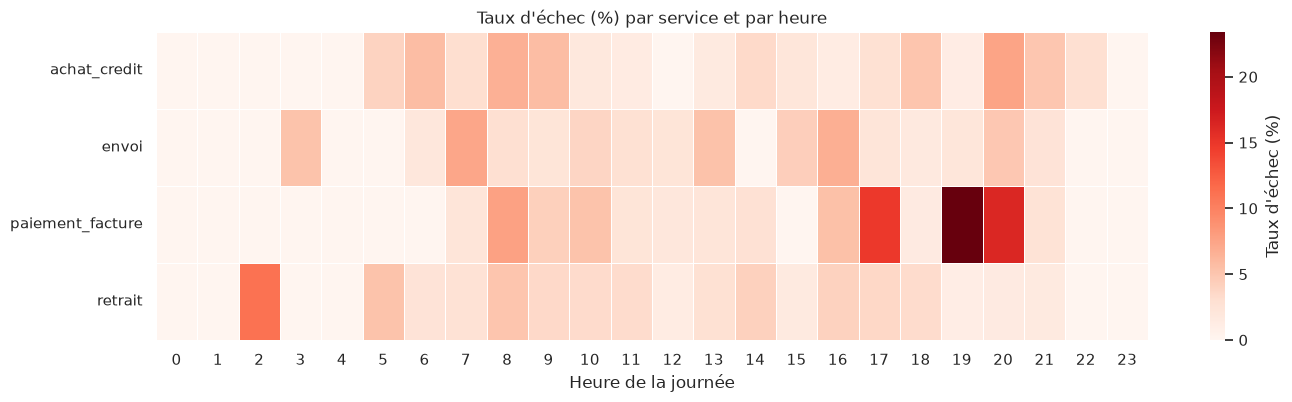

In [22]:
taux_echec_type_heure = df.pivot_table(
    index="type_operation", columns="heure", values="echec", aggfunc="mean"
)
taux_echec_type_heure = taux_echec_type_heure * 100

plt.figure(figsize=(16, 4))
sns.heatmap(taux_echec_type_heure, cmap="Reds", linewidths=0.5, cbar_kws={"label": "Taux d'échec (%)"})
plt.title("Taux d'échec (%) par service et par heure")
plt.xlabel("Heure de la journée")
plt.ylabel("")
plt.savefig("graphiques/heatmap_echecs.png", dpi=100, bbox_inches="tight")
plt.show()

**Ce qu'on en retient :**

- Le **paiement de facture** est le service qui échoue le plus (5,7 %), les trois autres sont
  autour de 3 %.
- Sur la carte de chaleur, la zone la plus foncée est très nette : **paiement de facture à 19h et
  20h**.
- On voit aussi quelques cases isolées plus foncées ailleurs (retrait à 2h, par exemple). Ce sont des
  heures avec très peu de transactions, où un seul échec suffit à faire monter le taux : il ne faut
  pas en tirer de conclusion.

### 2.8 Zoom sur les paiements de facture le soir

La carte de chaleur montre une zone plus foncée sur les paiements de facture en soirée. On le
vérifie avec un graphique par heure (en rouge : 19h et 20h), puis en comparant directement le
créneau **19h-21h** au reste de la journée.

Attention : la nuit, il y a très peu de transactions. Un seul échec sur 5 transactions donne
déjà 20 %. On affiche donc aussi le nombre de transactions par heure pour ne pas sur-interpréter
ces heures-là.

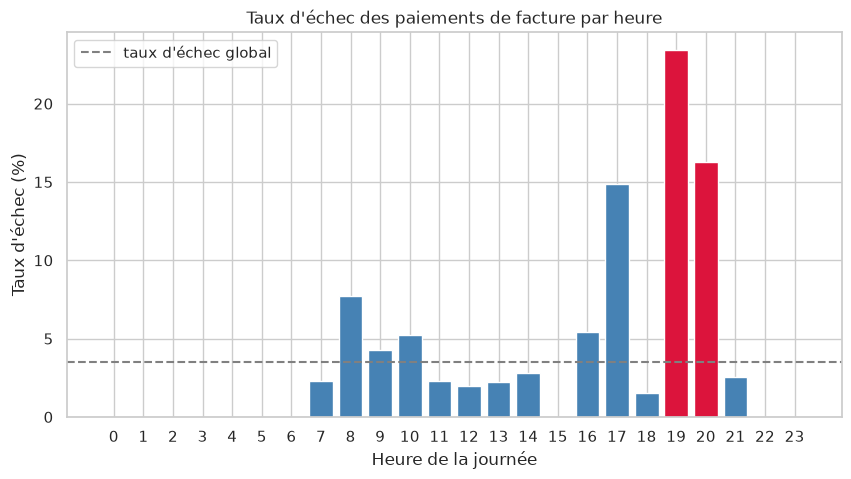

Nombre de paiements de facture par heure :
heure
0      8
1      3
2      7
3      3
4      4
5     10
6     12
7     44
8     52
9     47
10    38
11    43
12    51
13    45
14    36
15    36
16    37
17    47
18    66
19    47
20    43
21    39
22    15
23     8


In [23]:
factures = df[df["type_operation"] == "paiement_facture"]
taux_echec_factures = factures.groupby("heure")["echec"].mean() * 100
nombre_factures = factures.groupby("heure")["echec"].count()

couleurs_barres = []
for heure in taux_echec_factures.index:
    if heure == 19 or heure == 20:
        couleurs_barres.append(couleur_alerte)
    else:
        couleurs_barres.append(couleur)

plt.figure(figsize=(10, 5))
plt.bar(taux_echec_factures.index, taux_echec_factures.values, color=couleurs_barres)
plt.axhline(taux_echec, color="gray", linestyle="--", label="taux d'échec global")
plt.title("Taux d'échec des paiements de facture par heure")
plt.xlabel("Heure de la journée")
plt.ylabel("Taux d'échec (%)")
plt.xticks(range(24))
plt.legend()
plt.savefig("graphiques/echecs_factures_par_heure.png", dpi=100, bbox_inches="tight")
plt.show()

print("Nombre de paiements de facture par heure :")
print(nombre_factures.to_string())

In [24]:
comparaison = factures.groupby("est_le_soir")["echec"].agg(["count", "mean"])
comparaison = comparaison.rename(
    index={True: "19h-21h", False: "autres heures"},
    columns={"count": "nb_transactions", "mean": "taux_echec_pct"},
)
comparaison["taux_echec_pct"] = (comparaison["taux_echec_pct"] * 100).round(1)
comparaison

,nb_transactions,taux_echec_pct
est_le_soir,,
autres heures,651,3.7
19h-21h,90,20.0


In [25]:
autres_services = df[df["type_operation"] != "paiement_facture"]
taux_soir_autres = autres_services[autres_services["est_le_soir"]]["echec"].mean() * 100
print("Autres services entre 19h et 21h :", round(taux_soir_autres, 1), "% d'échec")

Autres services entre 19h et 21h : 3.2 % d'échec


**Ce qu'on en retient :**

- Entre **19h et 21h**, les paiements de facture échouent dans **20 % des cas**, contre **3,7 %**
  le reste de la journée : c'est **plus de 5 fois plus**.
- Ce n'est pas un problème général du soir : à la même heure, les **autres services** échouent
  seulement 3,2 % du temps. Le problème est propre aux **factures**.
- La barre de 17h est elle aussi haute (environ 15 %), mais elle repose sur seulement 47
  transactions : il faudrait plus de données pour savoir si c'est un vrai problème ou un hasard.
- Une hypothèse à vérifier : le service de paiement des factures (ou le partenaire qui reçoit les
  paiements) serait **surchargé** en début de soirée, juste après le pic d'activité de 18h.

### 2.9 Ce qu'il faut retenir

**Sur les données :**
- Le fichier brut avait cinq types de défauts (doublons, montants vides, montants négatifs, deux
  formats de date, villes mal écrites). Après nettoyage, il reste **5 000 transactions propres**.

**Sur l'activité :**
- Deux pics par jour, **vers 8h et entre 18h et 19h** ; peu de différence entre les jours de la
  semaine.
- **Cotonou** pèse près de 40 % des transactions.
- L'**envoi** est le service le plus fréquent, mais c'est le **retrait** qui fait circuler le plus
  d'argent.

**Sur les échecs :**
- Le taux d'échec global est faible (**3,5 %**), mais il cache un problème précis : les **paiements de
  facture échouent 5 fois plus souvent entre 19h et 21h** (20 % contre 3,7 %).
- Pour un opérateur, ce serait la première piste à creuser : vérifier la capacité du service de
  paiement des factures en soirée.

**Limite :** ces données sont fictives et le motif des factures a été placé volontairement dans le
générateur. L'intérêt du projet est d'avoir **retrouvé ce motif à partir des données brutes**, avec
la même méthode que sur un vrai dataset.